In [ ]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np
import scipy.io
import scipy.signal
import h5py
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from main import WindowedBPDataset, BPTransformer, visualize_finetuning


Loading Validation Dataset...
Loading Pig data for Time-Series Windowing...
  -> Loaded Pig 4 (74979 samples, Flow shifted by -21 timesteps)
  -> Loaded Pig 7 (74985 samples, Flow shifted by -15 timesteps)
  -> Loaded Pig 8 (74981 samples, Flow shifted by -19 timesteps)
Data loading complete! Total raw windows: 223448
Running Quality Control to remove corrupted sensor windows...
QC Complete: Removed 5060 corrupted windows.

Loading Model...
Successfully loaded saved weights!


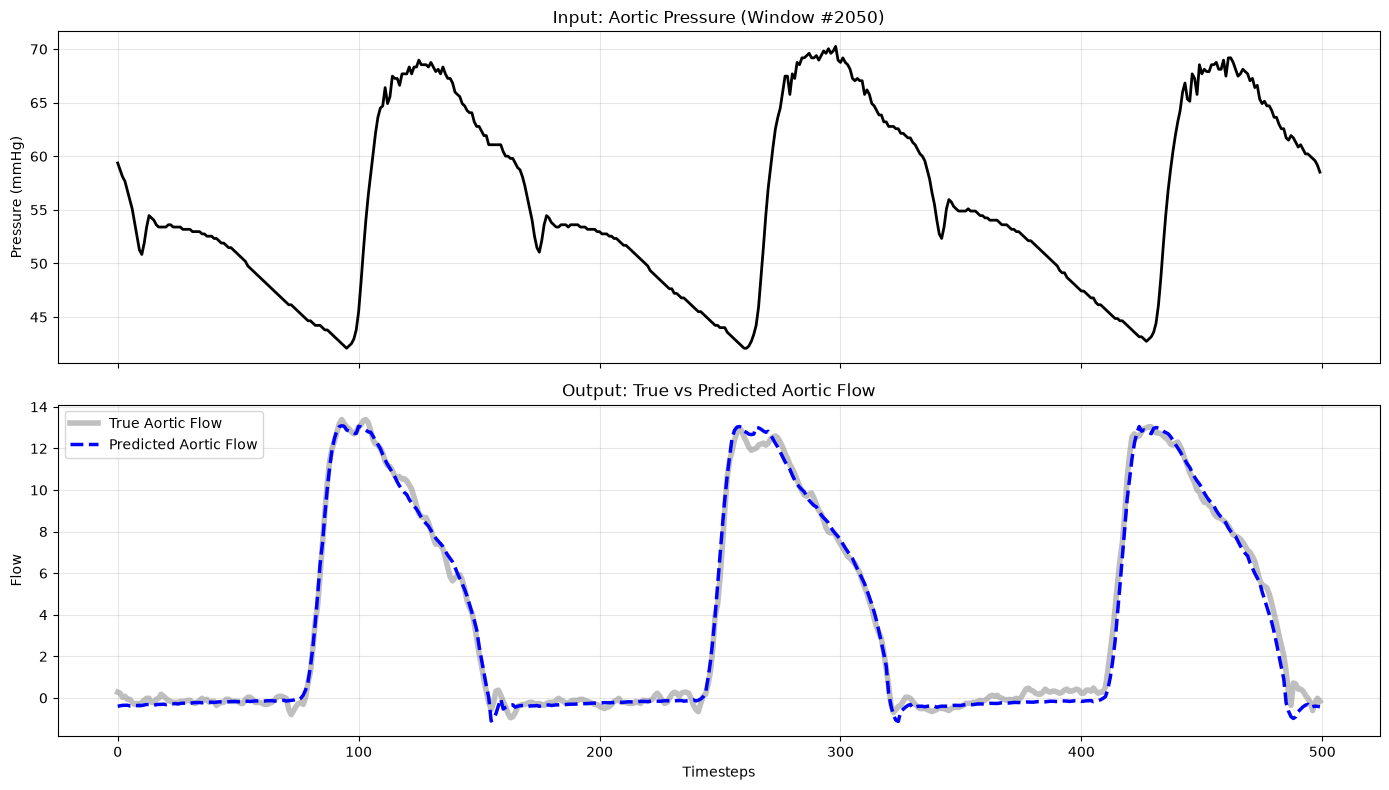

In [ ]:
# 1. Load the "Nice Pigs" Dataset (Pigs 4, 7, 8)
data_directory = "/Users/mboukaf/Desktop/Thesis/Codes/PigsBF/osfstorage-archive"
print("Loading Validation Dataset...")
dataset = WindowedBPDataset(data_dir=data_directory, pig_ids=[4, 7, 8], T=5)
# 2. Load the Fine-Tuned Model Weights
print("\nLoading Model...")
device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
model = BPTransformer(patch_size=5, window_size=500, n_layers=4, n_heads=4, mask_ratio=0.15)
model.to(device)
# Load the weights we saved earlier!
model_path = "finetuned_flow_model_pigs478.pth"
if os.path.exists(model_path):
    model.load_state_dict(torch.load(model_path, map_location=device))
    print("Successfully loaded saved weights!")
else:
    print("Warning: Model weights not found. Did main.py finish training?")
# 3. Visualize a random window from the clean dataset!
model.eval()
visualize_finetuning(model, dataset, index=2050)

Running inference on 500 random windows...


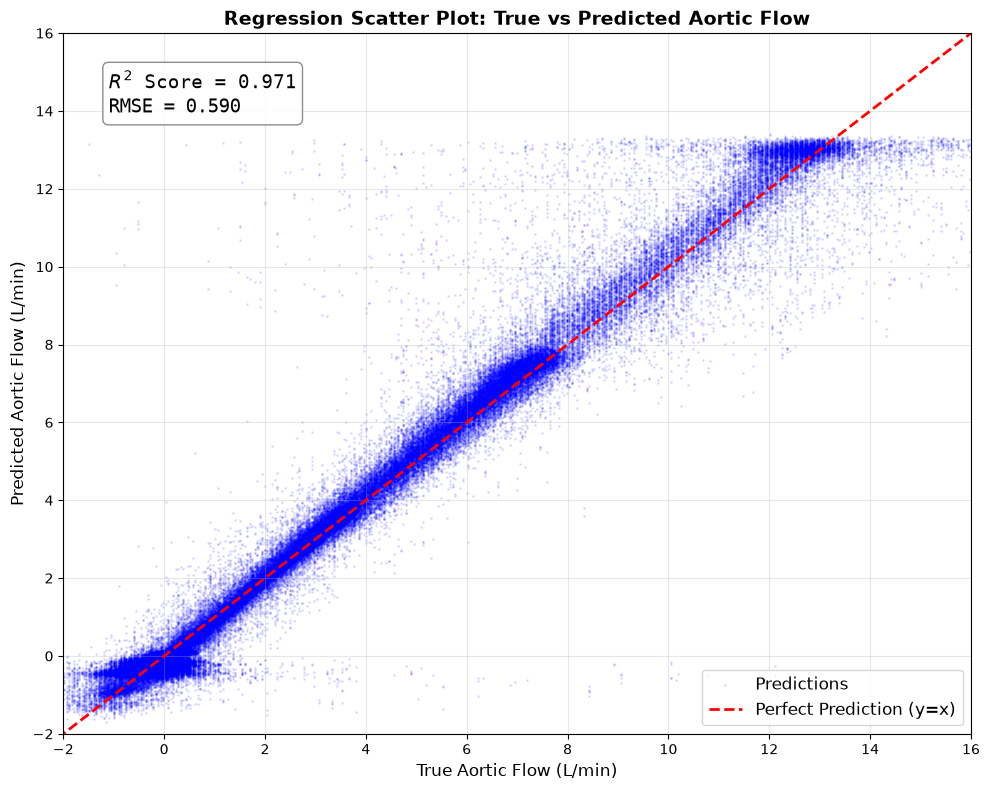

In [ ]:
import numpy as np
from sklearn.metrics import r2_score, mean_squared_error

# 1. Set model to evaluation mode
model.eval()

true_flows = []
pred_flows = []

# Evaluate 500 random windows (250,000 timesteps total)
num_windows_to_test = 500
print(f"Running inference on {num_windows_to_test} random windows...")

with torch.no_grad():
    for _ in range(num_windows_to_test):
        # Pick a random window
        idx = np.random.randint(0, len(dataset))
        x_real, y_real = dataset[idx]
        
        # Add batch dimension and send to device
        x_real = x_real.unsqueeze(0).to(device)
        
        # Predict Flow
        flow_predictions = model.forward_finetune(x_real)
        
        # Un-normalize the data back to real physiological values
        pred = flow_predictions.cpu().view(-1).numpy()
        true = y_real.cpu().view(-1).numpy()
        
        pred = (pred * dataset.y_std) + dataset.y_mean
        true = (true * dataset.y_std) + dataset.y_mean
        
        # Store for the scatter plot
        pred_flows.extend(pred)
        true_flows.extend(true)

# Convert to numpy arrays
true_flows = np.array(true_flows)
pred_flows = np.array(pred_flows)

# 2. Calculate Statistical Metrics
r2 = r2_score(true_flows, pred_flows)
rmse = np.sqrt(mean_squared_error(true_flows, pred_flows))

# 3. PLOTTING THE REGRESSION DENSITY PLOT
# 3. PLOTTING THE REGRESSION SCATTER PLOT
plt.figure(figsize=(10, 8))

# Standard Scatter Plot with tiny (s=1), semi-transparent (alpha=0.1) points
plt.scatter(true_flows, pred_flows, s=1, alpha=0.1, color='blue', label='Predictions')

# Draw the perfect y = x diagonal line
plt.plot([-5, 20], [-5, 20], color='red', linestyle='dashed', 
         linewidth=2, label='Perfect Prediction (y=x)')

plt.title("Regression Scatter Plot: True vs Predicted Aortic Flow", fontsize=14, fontweight='bold')
plt.xlabel("True Aortic Flow (L/min)", fontsize=12)
plt.ylabel("Predicted Aortic Flow (L/min)", fontsize=12)

# Lock axes to physiological ranges to ignore extreme sensor glitches
plt.xlim(-2, 16)
plt.ylim(-2, 16)

# Add metrics text box in the top left corner
textstr = f'$R^2$ Score = {r2:.3f}\nRMSE = {rmse:.3f}'
props = dict(boxstyle='round', facecolor='white', alpha=0.9, edgecolor='gray')
plt.text(0.05, 0.95, textstr, transform=plt.gca().transAxes, fontsize=14,
         verticalalignment='top', bbox=props, fontfamily='monospace')

plt.legend(loc='lower right', fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



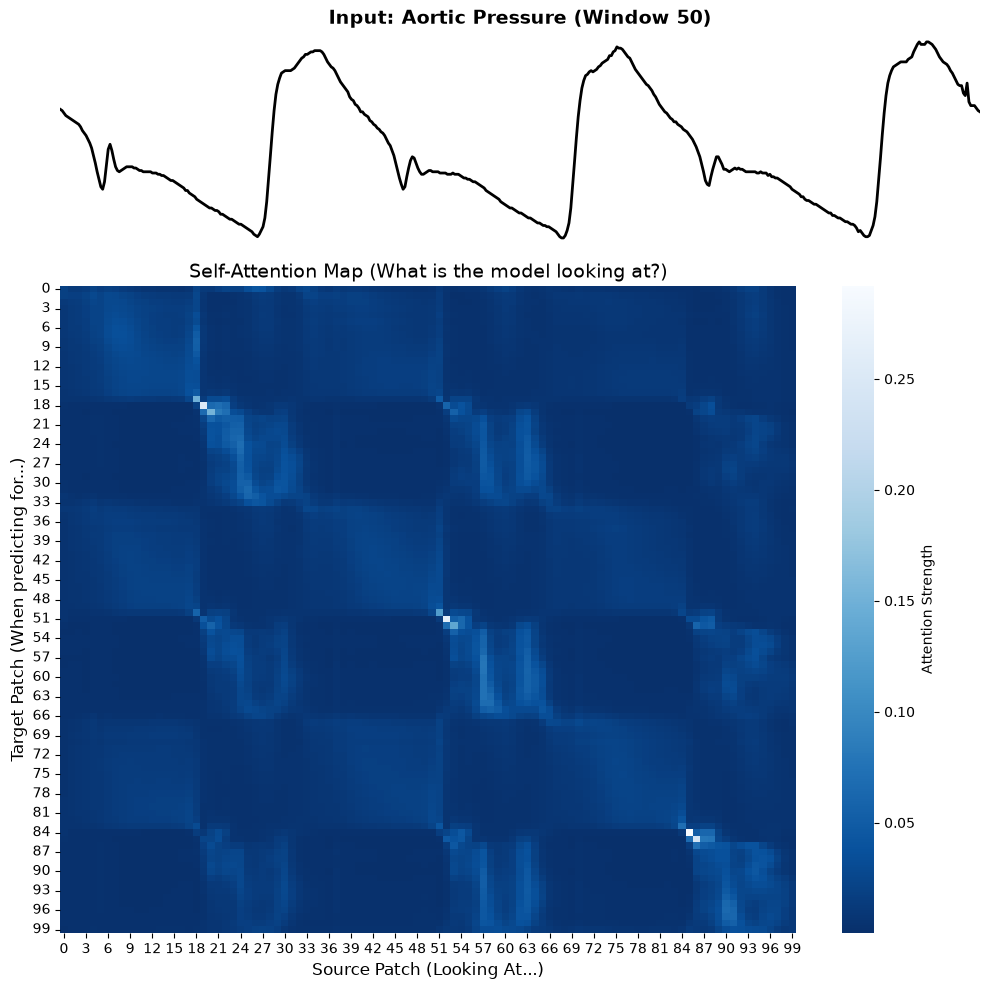

In [ ]:
import seaborn as plt_sns
import seaborn as sns
import matplotlib.pyplot as plt
import torch
import numpy as np

# 1. Select a random, clean window (e.g., index 150)
window_idx = 50
x_real, y_real = dataset[window_idx]
x_tensor = x_real.unsqueeze(0).to(device)

model.eval()
with torch.no_grad():
    # 2. Recreate the Forward Pass step-by-step up to the last layer
    x_embed = model.patch_embed(x_tensor)
    x_encoded = x_embed + model.pos_embed
    
      # Pass through all but the very last Transformer Layer
    hidden = x_encoded
    num_layers = len(model.transformer.layers)
    for i in range(num_layers - 1):
        hidden = model.transformer.layers[i](hidden)

        
    # 3. For the LAST layer, manually call Self-Attention and force it to return the Attention Matrix!
    last_layer = model.transformer.layers[-1]
    attn_output, attn_weights = last_layer.self_attn(
        hidden, hidden, hidden, 
        need_weights=True, 
        average_attn_weights=True # Averages the attention across all 4 heads
    )

# attn_weights is shape [1, 100, 100] (Batch, Target_Patches, Source_Patches). Squeeze to 2D.
attention_matrix = attn_weights.squeeze(0).cpu().numpy()

# 4. PLOTTING THE HEATMAP
# We create a stacked plot. The pressure wave goes on top, the heatmap goes below it!
fig, axes = plt.subplots(2, 1, figsize=(10, 10), gridspec_kw={'height_ratios': [1, 3]})

# Top Plot: The Input Pressure Wave (Scaled down to 100 patches to align perfectly with the heatmap)
time_axis = np.linspace(0, 100, len(x_real))
axes[0].plot(time_axis, x_real.numpy(), color='black', linewidth=2)
axes[0].set_title(f"Input: Aortic Pressure (Window {window_idx})", fontsize=14, fontweight='bold')
axes[0].set_xlim(0, 100)
axes[0].axis('off')

# Bottom Plot: The Attention Heatmap
sns.heatmap(attention_matrix, cmap='Blues_r', ax=axes[1], cbar_kws={'label': 'Attention Strength'})
axes[1].set_title("Self-Attention Map (What is the model looking at?)", fontsize=14)
axes[1].set_xlabel("Source Patch (Looking At...)", fontsize=12)
axes[1].set_ylabel("Target Patch (When predicting for...)", fontsize=12)

plt.tight_layout()
plt.show()


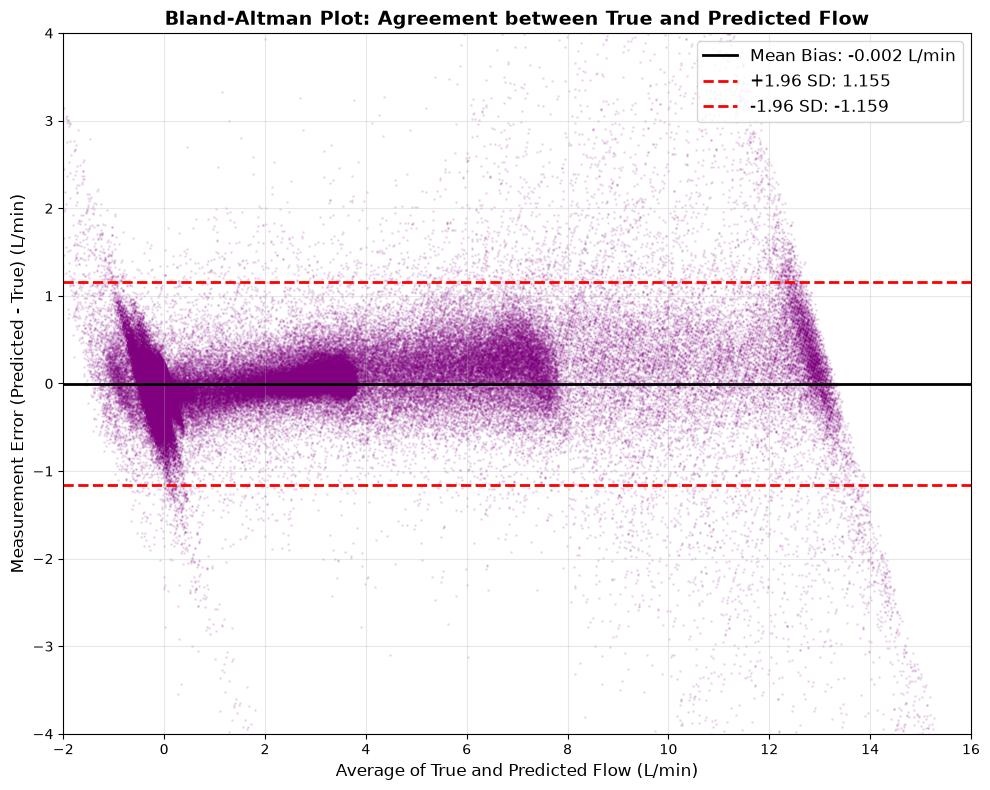

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Calculate Averages and Differences
means = (pred_flows + true_flows) / 2.0
diffs = pred_flows - true_flows

# 2. Calculate Clinical Statistics (Bias and 95% Limits of Agreement)
mean_diff = np.mean(diffs)
std_diff = np.std(diffs)
upper_limit = mean_diff + 1.96 * std_diff
lower_limit = mean_diff - 1.96 * std_diff

# 3. PLOTTING THE BLAND-ALTMAN PLOT
plt.figure(figsize=(10, 8))

# Scatter plot of the differences (tiny transparent dots for density)
plt.scatter(means, diffs, s=1, alpha=0.1, color='purple')

# Plot the Mean Bias line
plt.axhline(mean_diff, color='black', linestyle='-', linewidth=2, 
            label=f'Mean Bias: {mean_diff:.3f} L/min')

# Plot the 95% Limits of Agreement
plt.axhline(upper_limit, color='red', linestyle='dashed', linewidth=2, 
            label=f'+1.96 SD: {upper_limit:.3f}')
plt.axhline(lower_limit, color='red', linestyle='dashed', linewidth=2, 
            label=f'-1.96 SD: {lower_limit:.3f}')

plt.title("Bland-Altman Plot: Agreement between True and Predicted Flow", fontsize=14, fontweight='bold')
plt.xlabel("Average of True and Predicted Flow (L/min)", fontsize=12)
plt.ylabel("Measurement Error (Predicted - True) (L/min)", fontsize=12)

# Zoom in to ignore extreme sensor glitches
plt.xlim(-2, 16)
plt.ylim(-4, 4)

plt.legend(loc='upper right', fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
import os
import torch
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from sklearn.metrics import r2_score, mean_squared_error

from main import WindowedBPDataset, BPTransformer

# =============================================================================
# 1. LOAD DATASETS & MODEL
# =============================================================================
data_directory = "/Users/mboukaf/Desktop/Thesis/Codes/PigsBF/osfstorage-archive"
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

# Load the TIME SPLIT Data
train_dataset = WindowedBPDataset(data_dir=data_directory, pig_ids=[4, 7, 8], T=5, split_type="time", split="train") 
test_dataset = WindowedBPDataset(data_dir=data_directory, pig_ids=[4, 7, 8], T=5, split_type="time", split="test") 

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

# Load Model
model = BPTransformer(patch_size=5, window_size=500, n_layers=4, n_heads=4, mask_ratio=0.15).to(device)
model_path = "finetuned_flow_model_time_split.pth"
model.load_state_dict(torch.load(model_path, map_location=device))
model.eval()

# =============================================================================
# 2. EXTRACT PREDICTIONS (WITH SUBSAMPLING TO PREVENT CRASHES)
# =============================================================================
def get_predictions(dataloader):
    all_preds, all_trues = [], []
    with torch.no_grad():
        for x, y in dataloader:
            x, y = x.to(device), y.to(device)
            preds = model.forward_finetune(x)
            
            preds = preds.view(-1).cpu().numpy()
            trues = y.view(-1).cpu().numpy()
            
            # Un-normalize using the Train Dataset's physical statistics
            preds = (preds * train_dataset.y_std) + train_dataset.y_mean
            trues = (trues * train_dataset.y_std) + train_dataset.y_mean
            
            # Subsample by a factor of 50 to prevent matplotlib from freezing
            all_preds.extend(preds[::50])
            all_trues.extend(trues[::50])
            
    return np.array(all_trues), np.array(all_preds)

print("Extracting Train Set Predictions...")
train_true, train_pred = get_predictions(train_loader)
print("Extracting Test Set Predictions...")
test_true, test_pred = get_predictions(test_loader)

# Calculate Metrics
train_r2 = r2_score(train_true, train_pred)
train_rmse = np.sqrt(mean_squared_error(train_true, train_pred))
test_r2 = r2_score(test_true, test_pred)
test_rmse = np.sqrt(mean_squared_error(test_true, test_pred))

print(f"\nTrain R2: {train_r2:.3f} | Train RMSE: {train_rmse:.3f}")
print(f"Test R2:  {test_r2:.3f} | Test RMSE:  {test_rmse:.3f}")

# =============================================================================
# 3. PLOT 1: REGRESSION SCATTER OVERLAY
# =============================================================================
plt.figure(figsize=(10, 8))

# Plot Train (Grey, in background)
plt.scatter(train_true, train_pred, s=2, alpha=0.05, color='gray', label=f'Train Set (R²={train_r2:.3f})')
# Plot Test (Blue, overlaid on top)
plt.scatter(test_true, test_pred, s=2, alpha=0.1, color='blue', label=f'Test Set (R²={test_r2:.3f})')

plt.plot([-5, 20], [-5, 20], color='red', linestyle='dashed', linewidth=2, label='Perfect Prediction (y=x)')

plt.title("Generalization Scatter Plot: Train vs Test Set", fontsize=14, fontweight='bold')
plt.xlabel("True Aortic Flow (L/min)", fontsize=12)
plt.ylabel("Predicted Aortic Flow (L/min)", fontsize=12)
plt.xlim(-2, 16)
plt.ylim(-2, 16)

# Make legend dots fully opaque and visible
leg = plt.legend(loc='lower right', fontsize=12)
for handle in leg.legendHandles:
    if hasattr(handle, 'set_sizes'):
        handle.set_sizes([30.0])
        handle.set_alpha(1)

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# =============================================================================
# 4. PLOT 2: BLAND-ALTMAN OVERLAY
# =============================================================================
train_means = (train_pred + train_true) / 2.0
train_diffs = train_pred - train_true

test_means = (test_pred + test_true) / 2.0
test_diffs = test_pred - test_true

test_mean_diff = np.mean(test_diffs)
test_std_diff = np.std(test_diffs)

plt.figure(figsize=(10, 8))

# Plot Train (Grey, background)
plt.scatter(train_means, train_diffs, s=2, alpha=0.05, color='gray', label='Train Set Error')
# Plot Test (Purple, foreground)
plt.scatter(test_means, test_diffs, s=2, alpha=0.1, color='purple', label='Test Set Error')

# Clinical standard lines (Using Test Set statistics)
plt.axhline(test_mean_diff, color='black', linestyle='-', linewidth=2, label=f'Test Mean Bias: {test_mean_diff:.3f}')
plt.axhline(test_mean_diff + 1.96*test_std_diff, color='red', linestyle='dashed', linewidth=2, label=f'Test +1.96 SD: {test_mean_diff + 1.96*test_std_diff:.3f}')
plt.axhline(test_mean_diff - 1.96*test_std_diff, color='red', linestyle='dashed', linewidth=2, label=f'Test -1.96 SD: {test_mean_diff - 1.96*test_std_diff:.3f}')

plt.title("Bland-Altman Overlay: Train vs Test Set Generalization", fontsize=14, fontweight='bold')
plt.xlabel("Average of True and Predicted Flow (L/min)", fontsize=12)
plt.ylabel("Measurement Error (Predicted - True) (L/min)", fontsize=12)
plt.xlim(-2, 16)
plt.ylim(-4, 4)

leg = plt.legend(loc='upper right', fontsize=12)
for handle in leg.legendHandles:
    if hasattr(handle, 'set_sizes'):
        handle.set_sizes([30.0])
        handle.set_alpha(1)

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


TypeError: WindowedBPDataset.__init__() got an unexpected keyword argument 'split_type'